# 04 — Amplificadores: EDFA, ruído de ASE e SNR

Este notebook segue a aula (`docs/04-class/context.md`): "Amplificadores (EDFA, não usaremos
Raman): como se agrega ruído no EDFA, como se calcula a SNR na saída e na entrada". O guia é
`docs/amplificadores.md`.

Regras usadas em todas as figuras (as mesmas dos notebooks anteriores):

- a física simulada vem **sempre** do pacote (`simcopy.kernels.amplifier`); o notebook só
  escreve as formas fechadas, que são a referência;
- forma fechada (linha) e simulação (pontos) juntas;
- as asserções numéricas ficam nos testes do pytest, escritos pelo grupo.

Fontes: Agrawal, *Sistemas de Comunicação por Fibra Óptica*, 4ª ed., seções 7.2.3, 7.4 e 7.5
(citado pelo número da equação), e o notebook do professor `4_EDFAsAndReceivers`. O texto
separa **fato** (com a fonte) de **dedução**.

**Ainda não há bloco de amplificador** (`components/optical`): a configuração depende das
dúvidas do guia. Aqui só o kernel.

## 0. Modelo

**[Fato: notebook do professor, seção 1]** O EDFA é um amplificador ideal mais uma fonte de
ruído aditiva: $s_{out}(t) = \sqrt{G}\,s_{in}(t) + n_{ASE}(t)$, com $n_{ASE}$ ruído branco
gaussiano.

**[Fato: Agrawal, Eq. 7.2.11 e 7.2.15]** A densidade espectral da emissão espontânea
amplificada (ASE) é $S_{ASE} = n_{sp}h\nu_0(G - 1)$, e a figura de ruído é
$F_n = 2n_{sp}(1 - 1/G) + 1/G \approx 2n_{sp}$ (mínimo de 3 dB, com $n_{sp} = 1$).

**[Fato: Agrawal, Eq. 7.4.1 e 7.5.10]** A potência total de ASE numa banda $\Delta\nu$ é
$2S_{ASE}\Delta\nu$: "o fator 2 leva em conta a natureza despolarizada da ASE". Ou seja,
$S_{ASE}$ é a densidade **por polarização**.

O kernel `amplify` multiplica o campo por $\sqrt{G}$ e soma, em cada polarização, ruído
gaussiano circular de densidade $S_{ASE}$ na banda inteira da grade (largura $f_s$).
**[Dedução, da Eq. 7.2.15]** Para um $F_n$ dado, $n_{sp} = (GF_n - 1)/[2(G - 1)]$
(`nsp_from_noise_figure`); o professor usa a aproximação $n_{sp} = F_n/2$.

**[Fato: notebook do professor e `draft.py`]** O ruído do professor é sorteado com
`np.random.rand` (uniforme em [0, 1), média não nula); a arquitetura registra isso como o
defeito P-1 e a correção C-2 (gaussiano circular), que é a do kernel.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simcopy.kernels.amplifier import ase_psd, nsp_from_noise_figure, amplify
from simcopy.kernels.ssfm import propagate, FiberKernelParams
from simcopy.core.grid import TimeGrid
from simcopy.core.units import H_PLANCK, Q_ELECTRON, db_per_m_to_np_per_m

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "legend.fontsize": 7.5})
C3 = ["tab:blue", "tab:orange", "tab:green"]
F0 = 193.1e12                       # Hz, frequência da portadora (hν)
HNU = H_PLANCK * F0
FS, N = 100e9, 2 ** 18              # grade de 100 GHz, 2,6 µs
grade = TimeGrid(FS, N)
f = grade.freq
dbm = lambda p: 10 * np.log10(p) + 30
w = lambda p_dbm: 10 ** ((p_dbm - 30) / 10)
lin = lambda db: 10 ** (db / 10)

def edfa(campo, G_db, NF_db, seed):
    """Ganho G_db e figura de ruído NF_db (n_sp exato da Eq. 7.2.15)."""
    G = lin(G_db)
    S = ase_psd(nsp_from_noise_figure(lin(NF_db), G), G, F0)
    return amplify(campo, G, S, FS, np.random.default_rng(seed)), S

def portadora(p):
    """Portadora CW sem ruído de fase, toda na polarização X (como o laser do pacote)."""
    x = np.zeros((2, N), dtype=complex)
    x[0] = np.sqrt(p)
    return x

def potencia_na_banda(campo, largura, centro=0.0):
    """Potência [W] das duas polarizações na banda [centro ± largura/2], pela FFT."""
    m = np.abs(f - centro) < largura / 2
    return np.sum(np.abs(np.fft.fft(campo, axis=1)[:, m]) ** 2) / N ** 2

print(f"hν = {HNU:.4e} J | grade: {FS/1e9:.0f} GHz, {N} amostras, resolução {FS/N/1e3:.0f} kHz")

hν = 1.2795e-19 J | grade: 100 GHz, 262144 amostras, resolução 381 kHz


## 1. Como o ruído se agrega: a ASE

Primeiro, só o ruído: o amplificador com entrada nula (G = 20 dB, NF = 5 dB). Pelo modelo, a
saída é ruído branco: espectro plano em $S_{ASE}$ em cada polarização, quadraturas
gaussianas independentes e a mesma potência em X e Y (ASE despolarizada).

n_sp = 1.5921 (aproximação F/2 = 1.5811) | S_ASE = 2.0167e-17 W/Hz | P_X/(S f_s) = 1.0005, P_Y/(S f_s) = 1.0028


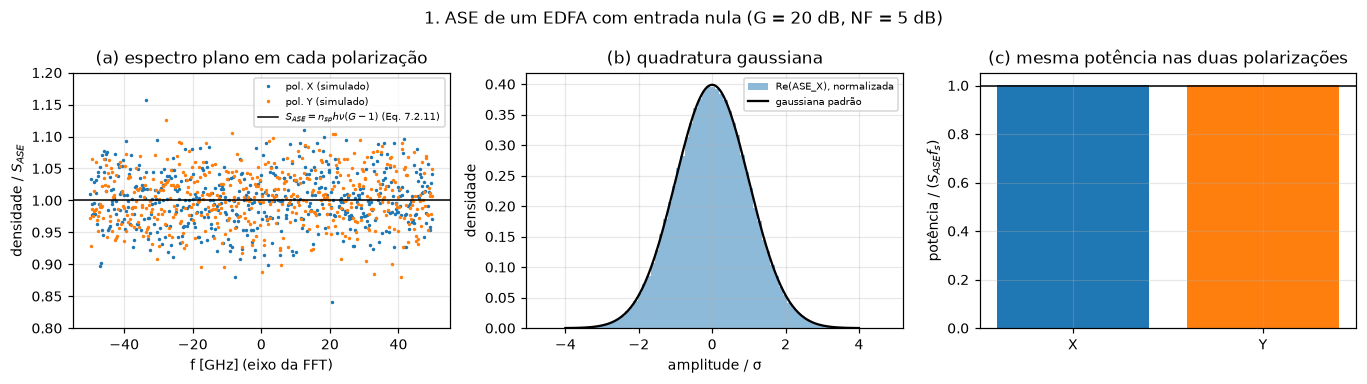

In [2]:
saida, S20 = edfa(np.zeros((2, N), dtype=complex), 20, 5, seed=0)
espec = np.abs(np.fft.fftshift(np.fft.fft(saida, axis=1), axes=1)) ** 2 / (N * FS)  # W/Hz
blocos = espec.reshape(2, 512, -1).mean(axis=2)                                      # média em 512 blocos
fb = np.fft.fftshift(f).reshape(512, -1).mean(axis=1)
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.5))
for k, nome in enumerate(["X", "Y"]):
    ax[0].plot(fb / 1e9, blocos[k] / S20, ".", ms=2.5, color=C3[k], label=f"pol. {nome} (simulado)")
ax[0].axhline(1.0, color="k", lw=1, label=r"$S_{ASE} = n_{sp}h\nu(G-1)$ (Eq. 7.2.11)")
ax[0].set(ylim=(0.8, 1.2), xlabel="f [GHz] (eixo da FFT)", ylabel=r"densidade / $S_{ASE}$",
          title="(a) espectro plano em cada polarização")
q = saida[0].real / np.sqrt(S20 * FS / 2)
xg = np.linspace(-4, 4, 200)
ax[1].hist(q, bins=80, density=True, color=C3[0], alpha=0.5, label="Re(ASE_X), normalizada")
ax[1].plot(xg, np.exp(-xg ** 2 / 2) / np.sqrt(2 * np.pi), "k-", label="gaussiana padrão")
ax[1].set(xlabel="amplitude / σ", ylabel="densidade", title="(b) quadratura gaussiana")
p_x, p_y = np.mean(np.abs(saida) ** 2, axis=1)
ax[2].bar([0, 1], np.array([p_x, p_y]) / (S20 * FS), color=C3[:2], tick_label=["X", "Y"])
ax[2].axhline(1.0, color="k", lw=1)
ax[2].set(ylabel=r"potência / ($S_{ASE}f_s$)", title="(c) mesma potência nas duas polarizações")
for a_ in ax[:2]: a_.legend(fontsize=6.5)
fig.suptitle("1. ASE de um EDFA com entrada nula (G = 20 dB, NF = 5 dB)")
fig.tight_layout()
print(f"n_sp = {nsp_from_noise_figure(lin(5), lin(20)):.4f} (aproximação F/2 = {lin(5)/2:.4f}) | "
      f"S_ASE = {S20:.4e} W/Hz | P_X/(S f_s) = {p_x/(S20*FS):.4f}, P_Y/(S f_s) = {p_y/(S20*FS):.4f}")

**Leitura.** A densidade medida é plana e igual a $S_{ASE}$ nas duas polarizações (a), as
quadraturas são gaussianas (b) e a potência se divide igualmente entre X e Y (c): é a ASE
despolarizada do Agrawal. Num campo (2, N), como o que o laser do pacote produz (com Y = 0),
a polarização Y passa a ter só ruído.

## 2. SNR óptica (OSNR) na entrada e na saída

**[Fato: Agrawal, seção 7.4]** A SNR óptica é a razão entre a potência do sinal e a da ASE
numa banda de referência. **[Dedução, das Eq. 7.2.11 e 7.4.1]** Com uma portadora de potência
$P_{in}$ e banda de referência $\Delta\nu_{ref}$ = 12,5 GHz (0,1 nm, a do professor), um
único amplificador dá

$$\mathrm{OSNR}_{out} = \frac{GP_{in}}{2S_{ASE}\Delta\nu_{ref}}
= \frac{GP_{in}}{2n_{sp}h\nu(G-1)\Delta\nu_{ref}} \approx \frac{P_{in}}{F_n h\nu\Delta\nu_{ref}}$$

Em dB, $\mathrm{OSNR} \approx 58 + P_{in}[\mathrm{dBm}] - NF[\mathrm{dB}]$, porque
$10\log_{10}(h\nu\Delta\nu_{ref}/1\,\mathrm{mW}) = -58$ dBm.

**[Dedução]** Se a entrada já tem ruído, com $\mathrm{OSNR}_{in}$, o amplificador
multiplica sinal e ruído por G e soma a ASE nova, de modo que
$1/\mathrm{OSNR}_{out} = 1/\mathrm{OSNR}_{in} + 2S_{ASE}\Delta\nu_{ref}/(GP_{in})$.

A medida usa a linearidade: a mesma semente sem o sinal dá só a ASE, cuja potência na banda
de referência é medida pela FFT. A entrada ruidosa é montada como no `set_OSNR` do professor:
ruído branco nas duas polarizações com a densidade que dá a OSNR pedida.

P_in = −20 dBm, NF = 5 dB: OSNR medida 32.963 dB | dedução 32.974 dB | regra 58 + P − NF = 33 dB


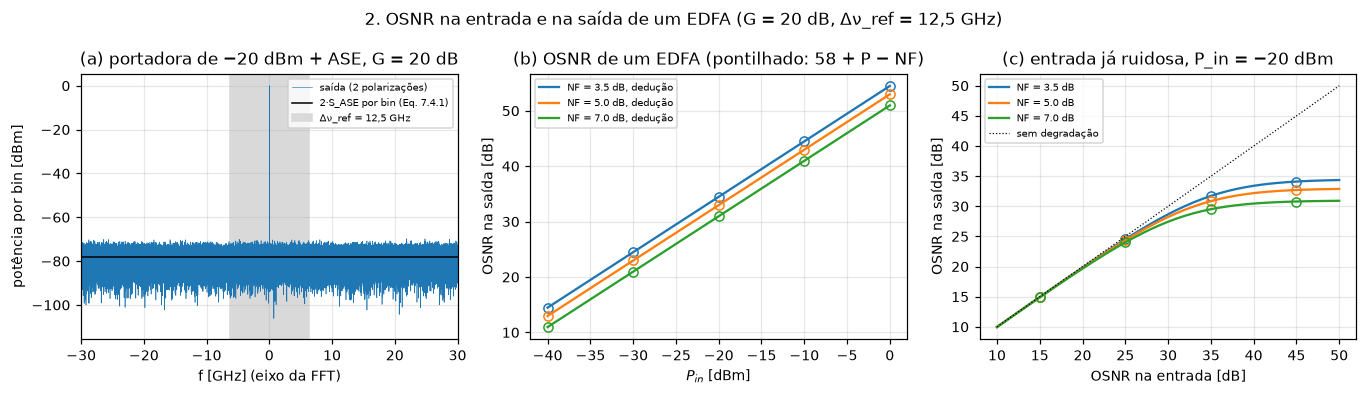

In [3]:
BREF = 12.5e9
ZERO = np.zeros((2, N), dtype=complex)
def osnr_medida(entrada, ruido_entrada, G_db, NF_db, seed):
    """OSNR na saída: potência do sinal sobre a do ruído na banda de referência. Com a mesma
    semente, saída com sinal menos saída sem sinal é o sinal amplificado, exatamente."""
    out, S = edfa(entrada + ruido_entrada, G_db, NF_db, seed)
    so_ruido, _ = edfa(ruido_entrada, G_db, NF_db, seed)
    p_sig = np.mean(np.abs(out - so_ruido) ** 2, axis=1).sum()
    return p_sig / potencia_na_banda(so_ruido, BREF), S

def ruido_com_osnr(p_in, osnr_db, seed):
    """Ruído branco nas duas polarizações com OSNR pedida em 12,5 GHz (como o set_OSNR)."""
    eta = p_in / lin(osnr_db) / (2 * BREF)                   # densidade por polarização
    r = np.random.default_rng(seed)
    return np.sqrt(eta * FS / 2) * (r.standard_normal((2, N)) + 1j * r.standard_normal((2, N)))

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.6))
# (a) espectro na saída
out_a, S_a = edfa(portadora(w(-20)), 20, 5, seed=1)
Ea = np.fft.fftshift(np.sum(np.abs(np.fft.fft(out_a, axis=1)) ** 2, axis=0)) / N ** 2
fa = np.fft.fftshift(f)
ax[0].plot(fa / 1e9, dbm(Ea + 1e-30), lw=0.4, color=C3[0], label="saída (2 polarizações)")
ax[0].axhline(dbm(2 * S_a * FS / N), color="k", lw=1, label="2·S_ASE por bin (Eq. 7.4.1)")
ax[0].axvspan(-BREF / 2e9, BREF / 2e9, color="0.85", zorder=0, label="Δν_ref = 12,5 GHz")
ax[0].set(xlim=(-30, 30), xlabel="f [GHz] (eixo da FFT)", ylabel="potência por bin [dBm]",
          title="(a) portadora de −20 dBm + ASE, G = 20 dB")
ax[0].legend(fontsize=6.5, loc="upper right")
# (b) OSNR na saída x potência de entrada
p_eixo = np.linspace(-40, 0, 41)
p_pts = np.array([-40, -30, -20, -10, 0])
for i, NF_db in enumerate([3.5, 5.0, 7.0]):
    G = lin(20); S = ase_psd(nsp_from_noise_figure(lin(NF_db), G), G, F0)
    ax[1].plot(p_eixo, 10 * np.log10(G * w(p_eixo) / (2 * S * BREF)), "-", color=C3[i],
               label=f"NF = {NF_db} dB, dedução")
    med = [osnr_medida(portadora(w(p)), ZERO, 20, NF_db, seed=10 + j)[0] for j, p in enumerate(p_pts)]
    ax[1].plot(p_pts, 10 * np.log10(med), "o", mfc="none", color=C3[i])
    ax[1].plot(p_eixo, 58 + p_eixo - NF_db, ":", color=C3[i], lw=0.8)
ax[1].set(xlabel="$P_{in}$ [dBm]", ylabel="OSNR na saída [dB]",
          title="(b) OSNR de um EDFA (pontilhado: 58 + P − NF)")
ax[1].legend(fontsize=6.5)
# (c) OSNR na saída x OSNR na entrada
oin = np.linspace(10, 50, 41)
oin_pts = np.array([15, 25, 35, 45])
for i, NF_db in enumerate([3.5, 5.0, 7.0]):
    G = lin(20); S = ase_psd(nsp_from_noise_figure(lin(NF_db), G), G, F0)
    ana = 1 / (1 / lin(oin) + 2 * S * BREF / (G * w(-20)))
    ax[2].plot(oin, 10 * np.log10(ana), "-", color=C3[i], label=f"NF = {NF_db} dB")
    med = [osnr_medida(portadora(w(-20)), ruido_com_osnr(w(-20), o, 100 + j), 20, NF_db, 200 + j)[0]
           for j, o in enumerate(oin_pts)]
    ax[2].plot(oin_pts, 10 * np.log10(med), "o", mfc="none", color=C3[i])
ax[2].plot(oin, oin, "k:", lw=0.8, label="sem degradação")
ax[2].set(xlabel="OSNR na entrada [dB]", ylabel="OSNR na saída [dB]",
          title="(c) entrada já ruidosa, P_in = −20 dBm")
ax[2].legend(fontsize=6.5)
fig.suptitle("2. OSNR na entrada e na saída de um EDFA (G = 20 dB, Δν_ref = 12,5 GHz)")
fig.tight_layout()
o_med, _ = osnr_medida(portadora(w(-20)), ZERO, 20, 5.0, seed=1)
print(f"P_in = −20 dBm, NF = 5 dB: OSNR medida {10*np.log10(o_med):.3f} dB | dedução "
      f"{10*np.log10(lin(20)*w(-20)/(2*S_a*BREF)):.3f} dB | regra 58 + P − NF = 33 dB")

**Leitura.**
- (a) O sinal é um único bin; a ASE forma um patamar plano em $2S_{ASE}$ por hertz (as duas
  polarizações). A OSNR compara o sinal com o ruído dentro da faixa cinza.
- (b) A OSNR de saída cresce dB a dB com a potência de entrada e cai dB a dB com a figura
  de ruído: a ASE não depende do sinal, então quanto mais fraco o sinal na entrada, pior. A
  regra "58 + P − NF" (pontilhado) fica a menos de 0,1 dB da expressão completa para G = 20 dB.
- (c) Com entrada muito ruidosa o amplificador quase não piora a OSNR (as curvas encostam na
  diagonal); com entrada limpa a saída satura no valor de (b). É o exercício 3 do professor.

## 3. Cadeia de amplificadores

**[Fato: Agrawal, Eq. 7.4.1–7.4.2]** Numa cadeia de $N_A$ amplificadores espaçados de $L_A$,
cada um com ganho $G = e^{\alpha L_A}$ (compensa exatamente o trecho de fibra), as ASE de
todos chegam ao fim com a mesma potência e se somam:

$$P_{ASE}^{tot} = 2N_A S_{ASE}\Delta\nu_o,\qquad
\mathrm{SNR}_o = \frac{P_{in}}{P_{ASE}^{tot}} = \frac{P_{in}\ln G}{2n_{sp}h\nu_0\Delta\nu_o\alpha L_T(G - 1)}$$

A OSNR cai 3 dB a cada vez que o número de amplificadores dobra. Para um enlace de
comprimento total $L_T$ fixo, a ASE total varia com $(G - 1)/\ln G$: trechos mais curtos (G
menor) dão menos ruído, apesar de mais amplificadores.

A simulação usa o kernel da fibra só com atenuação (0,2 dB/km) e o kernel do amplificador,
com $P_{in}$ = 0 dBm e NF = 5 dB.

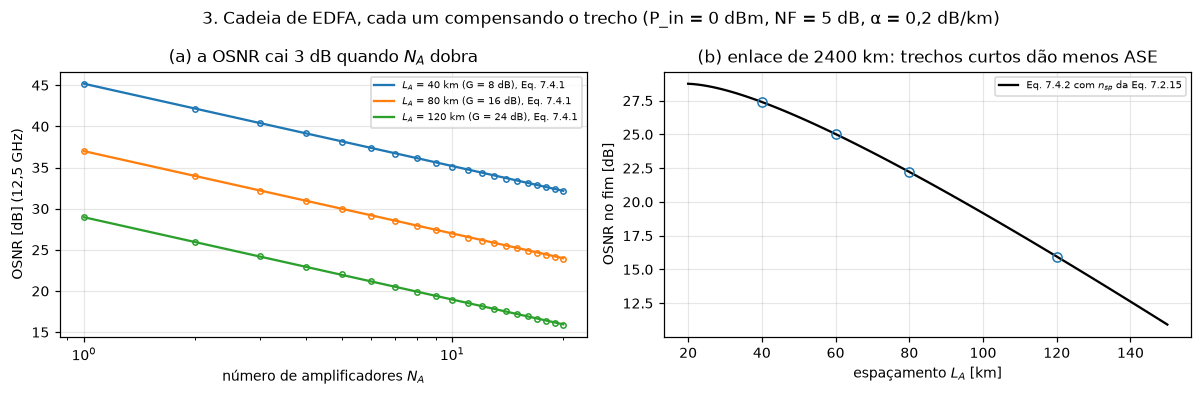

In [4]:
ALPHA = db_per_m_to_np_per_m(0.2e-3)
N3 = 2 ** 16
grade3 = TimeGrid(FS, N3)
om3, f3 = grade3.omega, grade3.freq

def cadeia(p_in, LA, n_amp, NF_db, seed):
    """OSNR (12,5 GHz) depois de cada um de n_amp trechos de fibra + EDFA."""
    G = np.exp(ALPHA * LA)
    S = ase_psd(nsp_from_noise_figure(lin(NF_db), G), G, F0)
    rng = np.random.default_rng(seed)
    ruido = np.zeros((2, N3), dtype=complex)                   # só a ASE (o sistema é linear)
    osnr = []
    m = np.abs(f3) < BREF / 2
    for _ in range(n_amp):
        ruido = propagate(ruido, om3, FiberKernelParams(LA, 0.0, 0.0, ALPHA))
        ruido = amplify(ruido, G, S, FS, rng)
        p_ase = np.sum(np.abs(np.fft.fft(ruido, axis=1)[:, m]) ** 2) / N3 ** 2
        osnr.append(p_in / p_ase)                              # o sinal volta a p_in a cada trecho
    return np.array(osnr), S, G

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, LA in enumerate([40e3, 80e3, 120e3]):
    o, S, G = cadeia(w(0), LA, 20, 5.0, seed=300 + i)
    na = np.arange(1, 21)
    ax[0].plot(na, 10 * np.log10(w(0) / (2 * na * S * BREF)), "-", color=C3[i],
               label=f"$L_A$ = {LA/1e3:.0f} km (G = {10*np.log10(G):.0f} dB), Eq. 7.4.1")
    ax[0].plot(na, 10 * np.log10(o), "o", ms=3.5, mfc="none", color=C3[i])
ax[0].set(xscale="log", xlabel="número de amplificadores $N_A$", ylabel="OSNR [dB] (12,5 GHz)",
          title="(a) a OSNR cai 3 dB quando $N_A$ dobra")
ax[0].legend(fontsize=6.5)
LT = 2400e3
LA_eixo = np.linspace(20e3, 150e3, 100)
G_eixo = np.exp(ALPHA * LA_eixo)
S_eixo = ase_psd(nsp_from_noise_figure(lin(5.0), G_eixo), G_eixo, F0)
ax[1].plot(LA_eixo / 1e3, 10 * np.log10(w(0) / (2 * (LT / LA_eixo) * S_eixo * BREF)), "k-",
           label="Eq. 7.4.2 com $n_{sp}$ da Eq. 7.2.15")
for LA in [40e3, 60e3, 80e3, 120e3]:
    o, _, _ = cadeia(w(0), LA, int(LT / LA), 5.0, seed=int(LA))
    ax[1].plot(LA / 1e3, 10 * np.log10(o[-1]), "o", mfc="none", color=C3[0])
ax[1].set(xlabel="espaçamento $L_A$ [km]", ylabel="OSNR no fim [dB]",
          title=f"(b) enlace de {LT/1e3:.0f} km: trechos curtos dão menos ASE")
ax[1].legend(fontsize=6.5)
fig.suptitle("3. Cadeia de EDFA, cada um compensando o trecho (P_in = 0 dBm, NF = 5 dB, α = 0,2 dB/km)")
fig.tight_layout()

**Leitura.** (a) Cada amplificador soma a mesma ASE na saída (cada trecho atenua a ASE dos
anteriores tanto quanto o amplificador seguinte a recupera), por isso a OSNR cai com
$10\log_{10}N_A$. Trechos de 120 km precisam de 24 dB de ganho e começam 16 dB abaixo dos de
40 km. (b) Para o mesmo enlace de 2400 km, ir de 120 km para 40 km entre amplificadores
melhora a OSNR em ~11 dB, mesmo com o triplo de amplificadores: é o argumento do Agrawal
(texto após a Eq. 7.4.1) para reduzir o espaçamento, e a origem da vantagem da amplificação
distribuída.

## 4. SNR elétrica na entrada e na saída, e a figura de ruído

**[Fato: Agrawal, Eq. 7.2.8–7.2.10]** A figura de ruído é a razão entre as SNR elétricas na
entrada e na saída, medidas com um detector ideal ($R_d = q/h\nu$) limitado só por ruído de
disparo: $F_n = \mathrm{SNR}_{in}/\mathrm{SNR}_{out}$, com
$\mathrm{SNR}_{in} = P_{in}/(2h\nu\Delta f)$, Δf a banda elétrica.

**[Fato: Agrawal, Eq. 7.5.3–7.5.11]** Depois do amplificador e de um filtro óptico de banda
$\Delta\nu_o$, a fotocorrente tem, além do ruído de disparo, os batimentos sinal-ASE e
ASE-ASE:

$$\sigma^2_{sig-sp} = 4R_d^2GP_sS_{ASE}\Delta f,\qquad
\sigma^2_{sp-sp} = 4R_d^2S_{ASE}^2\Delta f(\Delta\nu_o - \Delta f/2),\qquad
\sigma_s^2 = 2qR_d(GP_s + P_{ASE})\Delta f$$

$$\mathrm{SNR}_{out} = \frac{R_d^2(GP_s + P_{ASE})^2}{\sigma^2_{sig-sp} + \sigma^2_{sp-sp} + \sigma_s^2},
\qquad P_{ASE} = 2S_{ASE}\Delta\nu_o$$

A simulação monta a fotocorrente $I = R_d(|E_x|^2 + |E_y|^2)$ do campo depois de um filtro
óptico retangular de 50 GHz e de um filtro elétrico retangular de 5 GHz. **Os batimentos saem
da simulação; o ruído de disparo ainda não**: ele é do fotodetector, que é o próximo bloco da
aula, e entra aqui pela Eq. 7.5.10.

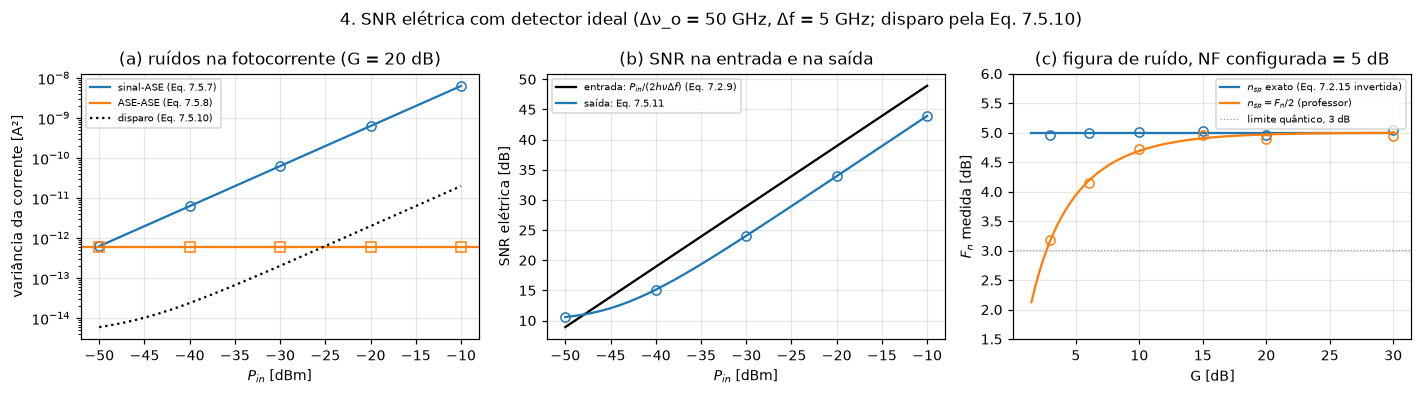

In [5]:
DVO, DF = 50e9, 5e9
RD = Q_ELECTRON / HNU
filtro_o = np.abs(f) <= DVO / 2
filtro_e = np.abs(f) <= DF

def fotocorrente(campo):
    E = np.fft.ifft(np.fft.fft(campo, axis=1) * filtro_o, axis=1)
    return np.fft.ifft(np.fft.fft(RD * np.sum(np.abs(E) ** 2, axis=0)) * filtro_e).real

def batimentos(p_in, G_db, n_sp, seed):
    """Variâncias simuladas: (sinal-ASE, ASE-ASE) e a densidade usada."""
    G = lin(G_db)
    S = ase_psd(n_sp, G, F0)
    r1, r2 = np.random.default_rng(seed), np.random.default_rng(seed)
    v_tot = np.var(fotocorrente(amplify(portadora(p_in), G, S, FS, r1)))
    v_spsp = np.var(fotocorrente(amplify(np.zeros((2, N), dtype=complex), G, S, FS, r2)))
    return v_tot - v_spsp, v_spsp, S, G

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) batimentos x potência de entrada
n_sp5 = nsp_from_noise_figure(lin(5), lin(20))
pp = np.linspace(-50, -10, 41)
S_ = ase_psd(n_sp5, lin(20), F0)
ax[0].semilogy(pp, 4 * RD ** 2 * lin(20) * w(pp) * S_ * DF, "-", color=C3[0], label="sinal-ASE (Eq. 7.5.7)")
ax[0].axhline(4 * RD ** 2 * S_ ** 2 * DF * (DVO - DF / 2), color=C3[1], label="ASE-ASE (Eq. 7.5.8)")
ax[0].semilogy(pp, 2 * Q_ELECTRON * RD * (lin(20) * w(pp) + 2 * S_ * DVO) * DF, ":", color="k",
               label="disparo (Eq. 7.5.10)")
for j, p in enumerate([-50, -40, -30, -20, -10]):
    vs, vn, _, _ = batimentos(w(p), 20, n_sp5, seed=400 + j)
    ax[0].plot(p, vs, "o", mfc="none", color=C3[0])
    ax[0].plot(p, vn, "s", mfc="none", color=C3[1])
ax[0].set(xlabel="$P_{in}$ [dBm]", ylabel="variância da corrente [A²]",
          title="(a) ruídos na fotocorrente (G = 20 dB)")
ax[0].legend(fontsize=6.5)
# (b) SNR na entrada e na saída x potência de entrada
snr_in = w(pp) / (2 * HNU * DF)
def snr_out_ana(p, G, n_sp):
    S = ase_psd(n_sp, G, F0)
    pase = 2 * S * DVO
    v = (4 * RD ** 2 * G * p * S * DF + 4 * RD ** 2 * S ** 2 * DF * (DVO - DF / 2)
         + 2 * Q_ELECTRON * RD * (G * p + pase) * DF)
    return (RD * (G * p + pase)) ** 2 / v
ax[1].plot(pp, 10 * np.log10(snr_in), "k-", label="entrada: $P_{in}/(2h\\nu\\Delta f)$ (Eq. 7.2.9)")
ax[1].plot(pp, 10 * np.log10(snr_out_ana(w(pp), lin(20), n_sp5)), "-", color=C3[0],
           label="saída: Eq. 7.5.11")
for j, p in enumerate([-50, -40, -30, -20, -10]):
    vs, vn, S, G = batimentos(w(p), 20, n_sp5, seed=500 + j)
    pase = 2 * S * DVO
    snr = (RD * (G * w(p) + pase)) ** 2 / (vs + vn + 2 * Q_ELECTRON * RD * (G * w(p) + pase) * DF)
    ax[1].plot(p, 10 * np.log10(snr), "o", mfc="none", color=C3[0])
ax[1].set(xlabel="$P_{in}$ [dBm]", ylabel="SNR elétrica [dB]", title="(b) SNR na entrada e na saída")
ax[1].legend(fontsize=6.5)
# (c) figura de ruído medida x ganho
Gs = np.array([3, 6, 10, 15, 20, 30])
G_eixo = np.linspace(1.5, 30, 100)
for i, (rot, nsp_fn) in enumerate([("$n_{sp}$ exato (Eq. 7.2.15 invertida)", lambda G: nsp_from_noise_figure(lin(5), G)),
                                    ("$n_{sp} = F_n/2$ (professor)", lambda G: lin(5) / 2)]):
    Fana = [2 * nsp_fn(lin(g)) * (1 - 1 / lin(g)) + 1 / lin(g) for g in G_eixo]
    ax[2].plot(G_eixo, 10 * np.log10(Fana), "-", color=C3[i], label=rot)
    Fmed = []
    for j, g in enumerate(Gs):
        vs, vn, S, G = batimentos(w(-20), g, nsp_fn(lin(g)), seed=600 + 10 * i + j)
        pase = 2 * S * DVO
        snr = (RD * (G * w(-20) + pase)) ** 2 / (vs + vn + 2 * Q_ELECTRON * RD * (G * w(-20) + pase) * DF)
        Fmed.append(w(-20) / (2 * HNU * DF) / snr)
    ax[2].plot(Gs, 10 * np.log10(Fmed), "o", mfc="none", color=C3[i])
ax[2].axhline(10 * np.log10(2), color="0.6", ls=":", lw=0.8, label="limite quântico, 3 dB")
ax[2].set(ylim=(1.5, 6), xlabel="G [dB]", ylabel="$F_n$ medida [dB]",
          title="(c) figura de ruído, NF configurada = 5 dB")
ax[2].legend(fontsize=6.5)
fig.suptitle("4. SNR elétrica com detector ideal (Δν_o = 50 GHz, Δf = 5 GHz; disparo pela Eq. 7.5.10)")
fig.tight_layout()

**Leitura.**
- (a) As variâncias simuladas de sinal-ASE (círculos) e de ASE-ASE (quadrados) seguem as
  Eq. 7.5.7 e 7.5.8. O batimento sinal-ASE cresce com a potência do sinal; o ASE-ASE não
  depende dele e só pesa quando o sinal é fraco (abaixo de −50 dBm aqui, onde os dois se
  igualam). O ruído de disparo fica abaixo dos dois em todas as potências.
- (b) A SNR de entrada é a do ruído de disparo (Eq. 7.2.9). A de saída fica 5 dB abaixo dela
  (a figura de ruído) enquanto o sinal-ASE domina. Para entradas fracas a curva se afasta:
  **[Dedução]** o numerador da Eq. 7.5.11, $R_d(GP_s + P_{ASE})$, conta a corrente média da
  ASE como se fosse sinal; em −50 dBm ela já é dois terços da corrente ($P_{ASE}$ = 2 µW
  contra $GP_s$ = 1 µW), e a "SNR" de saída passa
  da de entrada sem que o sinal tenha melhorado.
- (c) Com o $n_{sp}$ obtido invertendo a Eq. 7.2.15, a figura de ruído medida é a configurada
  (5 dB) em qualquer ganho. Com a aproximação $n_{sp} = F_n/2$ do professor, ela cai em ganho
  baixo: em G = 3 dB, a NF real fica 1,8 dB abaixo da configurada. **[Decidido: Gabriel,
  2026-10-22]** O projeto usa a do Agrawal (Eq. 7.2.15 invertida). Acima de
  ~15 dB as duas coincidem.

Testes: issue #19.